In [1]:
# Import required libaries
import pandas as pd
import numpy as np
from sklearn.mixture import GaussianMixture
import prince
import warnings
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# loading in the (anonymized) data
df = pd.read_csv("P1_2425_C1_Answers_Anon.csv")

# Shape of data
print("Shape of data:\n",df.shape)
print("Number of students:\n",df.shape[0])

#Ignore warnings
warnings.filterwarnings('ignore')

# First 5 rows of whole data set (including exam questions + survey questions)
df.head()

Shape of data:
 (184, 42)
Number of students:
 184


,Student number,1,2,5,6,7,8,9,10,11,...,37,38,39,40,49,50,51,52,53,54
0,0,A,A,B,A,a,b,A,A,c,...,A,B,B,B,A,A,B,EFC,E,C
1,1,A,A,B,b,B,A,A,A,B,...,b,B,B,B,A,A,B,DABCEF,E,D
2,2,A,A,B,A,a,b,A,A,a,...,A,a,B,a,A,A,B,E,E,D
3,3,A,A,B,A,B,A,A,A,c,...,A,a,B,a,A,A,C,ABE,E,B
4,4,A,A,B,A,B,A,A,A,c,...,A,B,B,B,A,D,E,ADE,E,B


In [3]:

# Stating survey answers

questions = {'49':' I Consent',
             '50':'From 1 to 5, how do you evaluate your level of programming before taking the Programming 2 course?',
             '51':' From 1 to 5, how do you evaluate your current level of programming after taking the Programming 2 course?',
             '52':'Which of the following learning strategies did you use during the Programming 2 course?\nA: Revisiting the lecture slides\nB: Doing project practice extra exercises (at the end of each assignment)\nC: Reading the recommended literature\nD: Doing project lovelace exercises\nE: Attending to/watching the lectures\nF: Attending the practice sessions (on Wednesdays)',
             '53':'From 1 to 5, how often did you attend the lectures (or watch the lecture recording before the workgroups)?',
             '54':'From 1 to 5, how often did you attend the practice sessions?'}
survey_answers = df[['49','50','51','52','53','54']]
survey_answers_learning_strategies = df[['49','52','53','54']]
# Printing questions for clarity (A:1 - E:5)
for number,question in questions.items():
    print(f"question {number}:\n{question}\n")

# Head of survey data frame
survey_answers.head()

question 49:
 I Consent

question 50:
From 1 to 5, how do you evaluate your level of programming before taking the Programming 2 course?

question 51:
 From 1 to 5, how do you evaluate your current level of programming after taking the Programming 2 course?

question 52:
Which of the following learning strategies did you use during the Programming 2 course?
A: Revisiting the lecture slides
B: Doing project practice extra exercises (at the end of each assignment)
C: Reading the recommended literature
D: Doing project lovelace exercises
E: Attending to/watching the lectures
F: Attending the practice sessions (on Wednesdays)

question 53:
From 1 to 5, how often did you attend the lectures (or watch the lecture recording before the workgroups)?

question 54:
From 1 to 5, how often did you attend the practice sessions?



,49,50,51,52,53,54
0,A,A,B,EFC,E,C
1,A,A,B,DABCEF,E,D
2,A,A,B,E,E,D
3,A,A,C,ABE,E,B
4,A,D,E,ADE,E,B


In [4]:
print("Shape:\n",survey_answers_learning_strategies.shape)
survey_answers_learning_strategies.head()

Shape:
 (184, 4)


,49,52,53,54
0,A,EFC,E,C
1,A,DABCEF,E,D
2,A,E,E,D
3,A,ABE,E,B
4,A,ADE,E,B


In [5]:
# Keep only answers where student gave consent and with no NaN
survey_answers_learning_strategies = survey_answers_learning_strategies[survey_answers_learning_strategies["49"]=='A']
survey_answers_learning_strategies = survey_answers_learning_strategies.dropna()
print("Shape:",survey_answers_learning_strategies.shape)
print("Number of people who gave consent:",survey_answers_learning_strategies.shape[0])
print(f"Difference with total: {survey_answers.shape[0] - survey_answers_learning_strategies.shape[0]}, Percentage: {((survey_answers_learning_strategies.shape[0] / survey_answers.shape[0]) *100):.2f}%")
# Preprocessing
categorical_translation = {"A":1,
                           "B":2,
                           "C":3,
                           "D":4,
                           "E":5}

# Question 53 and 54 will be translated to numerical values
survey_answers_learning_strategies["53"] = survey_answers_learning_strategies["53"].replace(["A","B","C","D","E",],[1,2,3,4,5])
survey_answers_learning_strategies["54"] = survey_answers_learning_strategies["54"].replace(["A","B","C","D","E",],[1,2,3,4,5])
# Question 52 needs to be represented as 6 distinct columns to indicate if strategy was present (0=no 1=yes)
print("\nDifferent occurences question 52:",len(survey_answers_learning_strategies["52"].unique()))

answers_52 = ["A","B","C","D","E","F"]

for answer in answers_52:
    
    # Ones if the choice (A - F) is present in the answer
    ones = [1  if answer in x else 0 for x in survey_answers_learning_strategies["52"]]
    survey_answers_learning_strategies[f"52.{answer}"] = ones

print("Before",survey_answers_learning_strategies.head())

# Drop old column
survey_answers_learning_strategies = survey_answers_learning_strategies.drop('52', axis=1)
# Re order columns
cols = survey_answers_learning_strategies.columns.tolist()
cols = cols[3:] + cols[1:3] # first columns 52.answer,53,54
survey_answers_learning_strategies = survey_answers_learning_strategies[cols]

# column 53 and 54 need normalization (values between 0 and 1 instead of 1 till 5).
def normalize_0_1(col):
    return (col-1)/4
survey_answers_learning_strategies['53'] = normalize_0_1(survey_answers_learning_strategies['53'])
survey_answers_learning_strategies['54'] = normalize_0_1(survey_answers_learning_strategies['54'])
print("\nafter\n",survey_answers_learning_strategies.head())

Shape: (128, 4)
Number of people who gave consent: 128
Difference with total: 56, Percentage: 69.57%

Different occurences question 52: 54
Before   49      52  53  54  52.A  52.B  52.C  52.D  52.E  52.F
0  A     EFC   5   3     0     0     1     0     1     1
1  A  DABCEF   5   4     1     1     1     1     1     1
2  A       E   5   4     0     0     0     0     1     0
3  A     ABE   5   2     1     1     0     0     1     0
4  A     ADE   5   2     1     0     0     1     1     0

after
    52.A  52.B  52.C  52.D  52.E  52.F   53    54
0     0     0     1     0     1     1  1.0  0.50
1     1     1     1     1     1     1  1.0  0.75
2     0     0     0     0     1     0  1.0  0.75
3     1     1     0     0     1     0  1.0  0.25
4     1     0     0     1     1     0  1.0  0.25


In [6]:

survey_answers_learning_strategies.shape

(128, 8)

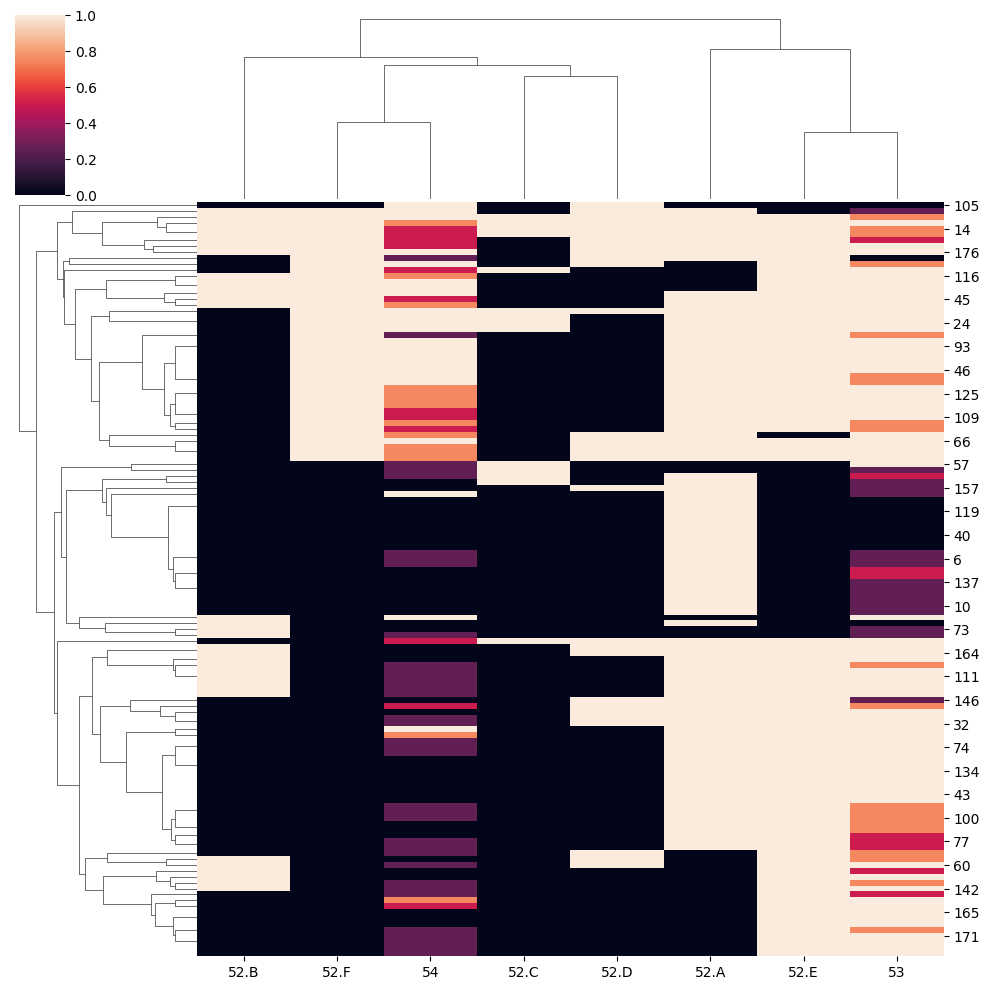

In [7]:
# Visualize data

sns.clustermap(survey_answers_learning_strategies)

In [8]:
# Data is categorical and discrete so MCA will be used before putting into a GMM
mca = prince.MCA(
    n_components=8,
    engine='sklearn',
    random_state=42,
    one_hot=False, # one hot encoding is done
    check_input=True,
    copy=True)
mca = mca.fit(survey_answers_learning_strategies)

In [9]:
mca.eigenvalues_summary

,eigenvalue,% of variance,% of variance (cumulative)
component,,,
0,0.240,24.67%,24.67%
1,0.229,23.57%,48.23%
2,0.169,17.41%,65.64%
3,0.161,16.60%,82.24%
4,0.122,12.53%,94.77%
5,0.038,3.92%,98.69%
6,0.013,1.31%,100.00%


In [10]:
mca.row_coordinates(survey_answers_learning_strategies).head()

,0,1,2,3,4,5,6
0,1.134803,0.255001,-0.084653,-0.537109,0.024905,-0.271995,0.025219
1,0.533890,0.417369,-0.088902,0.239524,-0.041931,-0.091907,-0.017162
2,-0.147806,0.058107,0.221913,-0.688185,0.366575,0.529405,-0.062034
3,-0.462038,0.246580,-0.556815,0.014334,0.005251,0.042753,-0.026670
4,-0.095990,-0.099933,0.374979,0.494622,0.530735,0.062012,0.051277


In [11]:
mca.column_coordinates(survey_answers_learning_strategies).head()

,0,1,2,3,4,5,6
52.A,-0.085144,-0.696243,-0.258176,0.355740,-0.178995,-0.004924,-0.015877
52.B,-0.596128,1.184508,-0.792502,0.302234,-0.334303,-0.013231,-0.015312
52.C,2.490446,0.354382,-0.860729,-0.012726,0.262735,-0.054965,-0.043829
52.D,0.165901,0.479444,0.836884,1.122336,0.445321,0.002751,0.022147
52.E,-0.208398,0.005465,0.054890,-0.304859,0.341163,-0.114221,-0.148644


In [12]:
mca.plot(
    survey_answers_learning_strategies,
    x_component=0,
    y_component=1,
    show_column_markers=True,
    show_row_markers=True,
    show_column_labels=False,
    show_row_labels=False,
)

alt.LayerChart(...)

In [13]:
mca.column_contributions_.style.format("{:.0%}")

,0,1,2,3,4,5,6
52.A,1%,46%,9%,17%,6%,0%,0%
52.B,11%,44%,27%,4%,7%,0%,0%
52.C,79%,2%,13%,0%,2%,0%,0%
52.D,1%,6%,26%,50%,10%,0%,0%
52.E,4%,0%,0%,12%,20%,7%,36%
52.F,2%,1%,16%,4%,34%,31%,2%
53,1%,0%,1%,9%,12%,1%,56%
54,1%,1%,8%,4%,10%,60%,5%


In [14]:
#  TO do: add correlation matrix